# Notebook 03 — Sensibilidad, LTspice y validación
**TP Integrador — Filtros analógicos activos · Grupo 3 · LP Chebyshev I, orden 3 (RC + seguidor y Sallen–Key $k=1$, TL072CP)**

Contenido:
1. Componentes y expresiones del circuito implementado (notebook 02).
2. **Sensibilidades simbólicas** $S_x^{\omega_r}$, $S_x^{\omega_0}$, $S_x^{Q}$ respecto de **cada** resistencia y capacitor, calculadas **antes** de imponer
   valores, y evaluadas en los componentes comerciales (incluidas las resistencias en serie y la resistencia del generador).
3. **Validación por perturbaciones finitas de ±1 %** sobre los polos del circuito completo (independiente de las fórmulas cerradas).
4. Sensibilidad de la magnitud $|H(j\omega)|$ y banda de dispersión esperada; efecto del GBW del AO.
5. **LTspice:** generación de netlists ejecutables (AO ideal, AO lineal de un polo y modelo PSpice de TI del TL072), verificación de los netlists con un
   solver nodal propio y lectura de los resultados de LTspice (`.raw`, `.log`) cuando estén disponibles.

In [1]:
import sys, json, re
from pathlib import Path
import numpy as np
import sympy as sp
import scipy
from scipy import signal
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | SciPy {scipy.__version__} | SymPy {sp.__version__} | "
      f"Matplotlib {matplotlib.__version__} | pandas {pd.__version__}")

KWR, KW0 = r'\omega_r', r'\omega_0'   # claves de parámetros (evita barras invertidas dentro de f-strings)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIG, RES, LTS = ROOT / 'figuras', ROOT / 'resultados', ROOT / 'ltspice'
for d_ in (FIG, RES, LTS, LTS / 'resultados'):
    d_.mkdir(exist_ok=True)

AZUL, NARANJA, VERDE, AMARILLO, MAGENTA, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#9a9a96'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 9, 'font.family': 'serif', 'mathtext.fontset': 'cm',
    'axes.grid': True, 'grid.color': '#d9d9d6', 'grid.linewidth': 0.6, 'axes.edgecolor': '#6b6b67',
    'axes.linewidth': 0.8, 'lines.linewidth': 1.6, 'legend.frameon': False,
    'axes.spines.top': False, 'axes.spines.right': False,
})
def guardar(fig, nombre):
    fig.savefig(FIG / f'{nombre}.pdf', bbox_inches='tight'); fig.savefig(FIG / f'{nombre}.png', bbox_inches='tight')
def num(x, nd=3):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return '---'
    x = 0.0 if abs(x) < 0.5 * 10**(-nd) else x
    t = f'{abs(x):.{nd}f}'.replace('.', '{,}')
    return ('$-$' + t) if x < 0 else t
def ing(x, unidad=''):
    for pref, f in [('M', 1e6), ('k', 1e3), ('', 1), ('m', 1e-3), ('µ', 1e-6), ('n', 1e-9), ('p', 1e-12)]:
        if abs(x) >= f * 0.9999:
            return f'{x / f:.4g} {pref}{unidad}'.strip().replace('.', ',')
    return f'{x:.3g} {unidad}'

Python 3.13.18 | NumPy 2.5.3 | SciPy 1.18.1 | SymPy 1.14.0 | Matplotlib 3.11.2 | pandas 3.0.5


## 1. Datos del notebook 02

In [2]:
DATOS = json.load(open(RES / 'componentes.json', encoding='utf-8'))
COMP, SERIE = DATOS['componentes'], DATOS['resistencias_en_serie']
PL, DIS = DATOS['plantilla'], DATOS['diseno']
print('Componentes:', {k: ing(v, 'F' if k.startswith('C') else 'Ω') for k, v in COMP.items()})
print('Resistencias en serie:', {k: [ing(x, 'Ω') for x in v] for k, v in SERIE.items()})
print('Diseño H_d:', DIS)

# Función de diseño H_d y de plantilla H_t (para comparar)
def cheby(Ap, fp):
    return signal.cheby1(int(DIS['N']), Ap, 2 * np.pi * fp, 'lowpass', analog=True, output='zpk')
ZPK_D, ZPK_T = cheby(DIS['Ap_d'], DIS['fp_d']), cheby(PL['Ap'], PL['fp'])
def resp(zpk, f):
    return signal.freqs_zpk(*zpk, worN=2 * np.pi * np.asarray(f, float))[1]

Componentes: {'Rs': '50 Ω', 'R0': '20,56 kΩ', 'C0': '10 nF', 'R1': '10,8 kΩ', 'R2': '7,36 kΩ', 'C1': '47 nF', 'C2': '4,7 nF'}
Resistencias en serie: {'R0': ['20 kΩ', '560 Ω'], 'R1': ['7,5 kΩ', '3,3 kΩ'], 'R2': ['6,8 kΩ', '560 Ω']}
Diseño H_d: {'Ap_d': 0.3, 'fp_d': 1060.0, 'N': 3, 'fr': 773.0339643046246, 'f0': 1200.1172900881495, 'Q': 1.5524767933938108}


## 2. Sensibilidades simbólicas
Expresiones del circuito (notebook 02, análisis nodal con AO ideal):
$$\omega_r = \frac{1}{C_0(R_0+R_s)},\qquad \omega_0 = \frac{1}{\sqrt{R_1R_2C_1C_2}},\qquad Q = \sqrt{\frac{C_1}{C_2}}\frac{\sqrt{R_1R_2}}{R_1+R_2},\qquad H(0)=1.$$
Sensibilidad normalizada: $S_x^P = \dfrac{x}{P}\dfrac{\partial P}{\partial x} = \dfrac{\partial \ln P}{\partial \ln x}$. Se calcula con SymPy **sobre las expresiones
generales** (sin imponer relaciones entre componentes) y después se evalúa. Para una resistencia formada por dos en serie, $R = R_a + R_b$:
$S^P_{R_a} = S^P_R \cdot R_a/R$ (regla de la cadena).

In [3]:
s = sp.symbols('s')
Rs, R0, C0, R1, R2, C1, C2 = sp.symbols('R_s R_0 C_0 R_1 R_2 C_1 C_2', positive=True)
Vi = sp.symbols('V_i'); V = sp.symbols('V1:7'); V1_, V2_, V3_, V4_, V5_, V6_ = V
eqs = [sp.Eq((Vi - V1_) / Rs, (V1_ - V2_) / R0), sp.Eq((V1_ - V2_) / R0, s * C0 * V2_), sp.Eq(V3_, V2_),
       sp.Eq((V3_ - V4_) / R1 + (V6_ - V4_) * s * C1 + (V5_ - V4_) / R2, 0),
       sp.Eq((V4_ - V5_) / R2, s * C2 * V5_), sp.Eq(V6_, V5_)]
sol = sp.solve(eqs, V, dict=True)[0]
Hc = sp.factor(sp.simplify(sol[V6_] / Vi))
wr_e = 1 / (C0 * (R0 + Rs))
w0_e = 1 / sp.sqrt(R1 * R2 * C1 * C2)
Q_e = sp.sqrt(C1 / C2) * sp.sqrt(R1 * R2) / (R1 + R2)
# Comprobación: el denominador de Hc coincide con (s+wr)(s^2 + w0/Q s + w0^2) normalizado
den_c = sp.Poly(sp.fraction(Hc)[1], s).monic().as_expr()
den_f = sp.expand((s + wr_e) * (s**2 + w0_e / Q_e * s + w0_e**2))
print('Expresiones cerradas consistentes con Hc:', sp.simplify(den_c - den_f) == 0)
print('H(0) =', sp.simplify(Hc.subs(s, 0)))

def S(P, x):
    return sp.simplify(x * sp.diff(P, x) / P)

ELEM = [Rs, R0, C0, R1, R2, C1, C2]
PARAM = {KWR: wr_e, KW0: w0_e, 'Q': Q_e}
SENS = {p: {x: S(P, x) for x in ELEM} for p, P in PARAM.items()}
for p in PARAM:
    for x in ELEM:
        if SENS[p][x] != 0:
            display(sp.Eq(sp.Symbol(f'S^{{{p}}}_{{{sp.latex(x)}}}'), SENS[p][x]))
print('Sensibilidad de la ganancia en continua H(0) = 1: nula respecto de todos los componentes.')

Expresiones cerradas consistentes con Hc: True
H(0) = 1


Eq(S^{\omega_r}_{R_{s}}, -R_s/(R_0 + R_s))

Eq(S^{\omega_r}_{R_{0}}, -R_0/(R_0 + R_s))

Eq(S^{\omega_r}_{C_{0}}, -1)

Eq(S^{\omega_0}_{R_{1}}, -1/2)

Eq(S^{\omega_0}_{R_{2}}, -1/2)

... (3 outputs left out)

Eq(S^{Q}_{R_{2}}, (R_1 - R_2)/(2*(R_1 + R_2)))

Eq(S^{Q}_{C_{1}}, 1/2)

Eq(S^{Q}_{C_{2}}, -1/2)

Sensibilidad de la ganancia en continua H(0) = 1: nula respecto de todos los componentes.


**Propiedades útiles** (apuntes de la cátedra): $\sum_{R} S^{\omega_0}_R = -1$ y $\sum_{C} S^{\omega_0}_C = -1$ (homogeneidad de grado $-1$ en $R$ y en $C$);
$\sum_R S^Q_R = \sum_C S^Q_C = 0$ ($Q$ es adimensional: no cambia con un escaleo de impedancia ni de frecuencia).

In [4]:
for p in PARAM:
    sR = sp.simplify(sum(SENS[p][x] for x in [Rs, R0, R1, R2]))
    sC = sp.simplify(sum(SENS[p][x] for x in [C0, C1, C2]))
    print(f'{p}: suma sobre R = {sR}, suma sobre C = {sC}')

\omega_r: suma sobre R = -1, suma sobre C = -1
\omega_0: suma sobre R = -1, suma sobre C = -1
Q: suma sobre R = 0, suma sobre C = 0


### 2.1 Evaluación en los componentes comerciales

In [5]:
VAL = {Rs: COMP['Rs'], R0: COMP['R0'], C0: COMP['C0'], R1: COMP['R1'], R2: COMP['R2'], C1: COMP['C1'], C2: COMP['C2']}
NOM = {Rs: 'R_s', R0: 'R_0', C0: 'C_0', R1: 'R_1', R2: 'R_2', C1: 'C_1', C2: 'C_2'}
filas = []
for x in ELEM:
    fila = {'elemento': NOM[x], 'valor': ing(VAL[x], 'F' if str(x).startswith('C') else 'Ω')}
    for p in PARAM:
        fila[f'S^{p}'] = float(SENS[p][x].subs(VAL))
    filas.append(fila)
# resistencias individuales de los pares en serie (regla de la cadena)
for ref, sym in [('R0', R0), ('R1', R1), ('R2', R2)]:
    if len(SERIE[ref]) > 1:
        for j, rj in enumerate(SERIE[ref]):
            fila = {'elemento': f'{NOM[sym]}{"ab"[j]}', 'valor': ing(rj, 'Ω')}
            for p in PARAM:
                fila[f'S^{p}'] = float(SENS[p][sym].subs(VAL)) * rj / VAL[sym]
            filas.append(fila)
tab_s = pd.DataFrame(filas)
tab_s.round(4)

,elemento,valor,S^\omega_r,S^\omega_0,S^Q
0,R_s,50 Ω,-0.0024,0.0000,0.0000
1,R_0,"20,56 kΩ",-0.9976,0.0000,0.0000
2,C_0,10 nF,-1.0000,0.0000,0.0000
3,R_1,"10,8 kΩ",0.0000,-0.5000,-0.0947
4,R_2,"7,36 kΩ",0.0000,-0.5000,0.0947
5,C_1,47 nF,0.0000,-0.5000,0.5000
6,C_2,"4,7 nF",0.0000,-0.5000,-0.5000
7,R_0a,20 kΩ,-0.9704,0.0000,0.0000
8,R_0b,560 Ω,-0.0272,0.0000,0.0000
9,R_1a,"7,5 kΩ",0.0000,-0.3472,-0.0658


Lectura: $\omega_r$ depende casi exclusivamente de $R_0$ y $C_0$ ($S=-1$; el generador aporta $S^{\omega_r}_{R_s} = -R_s/(R_0+R_s) \approx -0{,}002$).
$\omega_0$ tiene sensibilidad $-\tfrac12$ respecto de los cuatro elementos del Sallen–Key, independientemente del diseño. $Q$ depende de los
capacitores con $\pm\tfrac12$ y de las resistencias con apenas $\pm 0{,}095$ (gracias a $R_1\approx R_2$): **los componentes críticos son los
capacitores**, que además tienen la mayor tolerancia.

## 3. Validación por perturbaciones finitas de ±1 %
Para cada elemento $x$ se recalculan $\omega_r$, $\omega_0$ y $Q$ con $x(1\pm0{,}01)$ a partir de las **raíces del denominador** de $H_c(s)$
evaluado numéricamente (no de las fórmulas cerradas), y se estima $S \approx \dfrac{\ln P(x(1+\delta)) - \ln P(x(1-\delta))}{\ln(1+\delta) - \ln(1-\delta)}$
(diferencia central en escala logarítmica), además de las diferencias unilaterales $\pm1\,\%$.

In [6]:
den_poly = sp.Poly(sp.fraction(Hc)[1], s)
coef_f = sp.lambdify([Rs, R0, C0, R1, R2, C1, C2], den_poly.all_coeffs(), 'numpy')

def parametros_numericos(vals):
    c = np.array(coef_f(*[vals[x] for x in ELEM]), dtype=float)
    p = np.roots(c)
    pr = p[np.abs(p.imag) < 1e-9 * np.abs(p)].real[0]
    pc = p[p.imag > 0][0]
    return {KWR: -pr, KW0: abs(pc), 'Q': abs(pc) / (-2 * pc.real)}

P0 = parametros_numericos(VAL)
print('Nominal (raíces):', {k: f'{v:.6g}' for k, v in P0.items()},
      f"-> f_r = {P0[KWR]/2/np.pi:.2f} Hz, f_0 = {P0[KW0]/2/np.pi:.2f} Hz")
d = 0.01
filas = []
for x in ELEM:
    Pp = parametros_numericos({**VAL, x: VAL[x] * (1 + d)})
    Pm = parametros_numericos({**VAL, x: VAL[x] * (1 - d)})
    for p in PARAM:
        s_sym = float(SENS[p][x].subs(VAL))
        s_mas = (Pp[p] / P0[p] - 1) / d
        s_men = (Pm[p] / P0[p] - 1) / (-d)
        s_cen = (np.log(Pp[p]) - np.log(Pm[p])) / (np.log(1 + d) - np.log(1 - d))
        filas.append({'elemento': NOM[x], 'parámetro': p, 'S simbólica': s_sym, 'S (+1 %)': s_mas, 'S (−1 %)': s_men,
                      'S central': s_cen, 'Δ real +1 % [%]': 100 * (Pp[p] / P0[p] - 1), 'Δ lineal +1 % [%]': s_sym,
                      'error central': abs(s_cen - s_sym)})
val_fd = pd.DataFrame(filas)
print(f"Máximo |S_central - S_simbólica| = {val_fd['error central'].max():.2e}")
print(f"Máximo |S_(±1%) - S_simbólica| = {max((val_fd['S (+1 %)'] - val_fd['S simbólica']).abs().max(), (val_fd['S (−1 %)'] - val_fd['S simbólica']).abs().max()):.4f}")
val_fd[val_fd['S simbólica'].abs() > 1e-12].round(5)

Nominal (raíces): {'\\omega_r': '4852.01', '\\omega_0': '7546.6', 'Q': '1.55251'} -> f_r = 772.22 Hz, f_0 = 1201.08 Hz
Máximo |S_central - S_simbólica| = 1.28e-05
Máximo |S_(±1%) - S_simbólica| = 0.0101


,elemento,parámetro,S simbólica,S (+1 %),S (−1 %),S central,Δ real +1 % [%],Δ lineal +1 % [%],error central
0,R_s,\omega_r,-0.00243,-0.00243,-0.00243,-0.00243,-0.00243,-0.00243,0.00000
3,R_0,\omega_r,-0.99757,-0.98772,-1.00763,-0.99757,-0.98772,-0.99757,0.00000
6,C_0,\omega_r,-1.00000,-0.99010,-1.01010,-1.00000,-0.99010,-1.00000,0.00000
10,R_1,\omega_0,-0.50000,-0.49628,-0.50378,-0.50000,-0.49628,-0.50000,0.00000
11,R_1,Q,-0.09471,-0.09539,-0.09402,-0.09470,-0.09539,-0.09471,0.00001
13,R_2,\omega_0,-0.50000,-0.49628,-0.50378,-0.50000,-0.49628,-0.50000,0.00000
14,R_2,Q,0.09471,0.09309,0.09636,0.09472,0.09309,0.09471,0.00001
16,C_1,\omega_0,-0.50000,-0.49628,-0.50378,-0.50000,-0.49628,-0.50000,0.00000
17,C_1,Q,0.50000,0.49876,0.50126,0.50000,0.49876,0.50000,0.00000
19,C_2,\omega_0,-0.50000,-0.49628,-0.50378,-0.50000,-0.49628,-0.50000,0.00000


Las diferencias unilaterales difieren de la simbólica en el término de segundo orden ($\approx \tfrac12 \delta\, \partial S/\partial\ln x$); la
diferencia central lo cancela y coincide con la simbólica a menos de $10^{-4}$. Con ±1 % la aproximación lineal es excelente: el error de predicción del
cambio porcentual es del orden de centésimas de punto porcentual.

### 3.1 Efecto del GBW del AO
Con $A(s) = \omega_t/s$ en ambos AO (como en el notebook 02) se estima numéricamente $S^{P}_{\omega_t}$ por diferencia central ±1 %, y el
corrimiento absoluto de los parámetros respecto del caso ideal para el TL072CP (3 MHz, conservador).

In [7]:
At = sp.Symbol('A_t')
eqsA = eqs[:2] + [sp.Eq(V3_, At * (V2_ - V3_))] + eqs[3:5] + [sp.Eq(V6_, At * (V5_ - V6_))]
solA = sp.solve(eqsA, V, dict=True)[0]
HA = sp.simplify(solA[V6_] / Vi)
wt = sp.Symbol('omega_t', positive=True)
denA = sp.Poly(sp.fraction(sp.together(HA.subs(At, wt / s).subs(VAL)))[1], s)
coefA = sp.lambdify(wt, denA.all_coeffs(), 'numpy')

def param_gbw(ft):
    p = np.roots(np.array(coefA(2 * np.pi * ft), dtype=float))
    p = p[np.abs(p) < 1e5]                                       # polos del filtro (descarta los de los AO, ~MHz)
    pr = p[np.abs(p.imag) < 1e-6 * np.abs(p)].real
    pr = pr[np.argmin(np.abs(pr + P0[KWR]))]
    pc = p[p.imag > 0][0]
    return {KWR: -pr, KW0: abs(pc), 'Q': abs(pc) / (-2 * pc.real)}
GBW = 3e6
Pg, Pgp, Pgm = param_gbw(GBW), param_gbw(GBW * 1.01), param_gbw(GBW * 0.99)
filas = []
for p in PARAM:
    filas.append({'parámetro': p, 'desvío por GBW finito [%]': 100 * (Pg[p] / P0[p] - 1),
                  'S^P_GBW': (np.log(Pgp[p]) - np.log(Pgm[p])) / (np.log(1.01) - np.log(0.99))})
gbw_tab = pd.DataFrame(filas)
gbw_tab

,parámetro,desvío por GBW finito [%],S^P_GBW
0,\omega_r,-1.831868e-12,4.440744e-13
1,\omega_0,-7.661356e-02,7.660898e-04
2,Q,7.657703e-02,-7.641867e-04


## 4. Sensibilidad de la magnitud y banda de dispersión
La sensibilidad de la función $S^{H}_x(j\omega) = \dfrac{x}{H}\dfrac{\partial H}{\partial x}$ tiene parte real igual a $S^{|H|}_x(\omega)$; la variación de
$|H|$ en dB ante cambios relativos pequeños e independientes es
$\Delta|H|_{\mathrm{dB}} \approx \dfrac{20}{\ln 10}\sum_x S^{|H|}_x(\omega)\,\dfrac{\Delta x}{x}$. Con distribuciones uniformes de semiancho $t_x$,
$\sigma_x/x = t_x/\sqrt3$, y la desviación estándar de $|H|_{\mathrm{dB}}$ es $\dfrac{20}{\ln10}\sqrt{\sum_x \left(S^{|H|}_x\right)^2 \left(t_x/\sqrt3\right)^2}$.

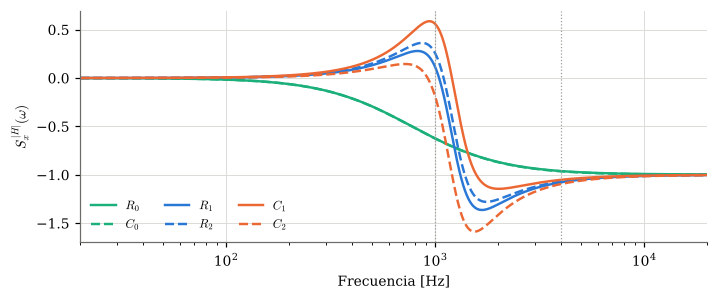

S^|H| en 1 kHz: {'R_0': np.float64(-0.624), 'C_0': np.float64(-0.626), 'R_1': np.float64(0.111), 'R_2': np.float64(0.253), 'C_1': np.float64(0.558), 'C_2': np.float64(-0.193)}
S^|H| en 4 kHz: {'R_0': np.float64(-0.962), 'C_0': np.float64(-0.964), 'R_1': np.float64(-1.077), 'R_2': np.float64(-1.069), 'C_1': np.float64(-1.052), 'C_2': np.float64(-1.095)}


In [8]:
f = np.geomspace(20, 2e4, 3000)
sj = 2j * np.pi * f
SH = {}
for x in [R0, C0, R1, R2, C1, C2]:
    SHx = sp.lambdify(s, sp.simplify(x * sp.diff(Hc, x) / Hc).subs(VAL), 'numpy')
    SH[NOM[x]] = np.real(SHx(sj))
fig, ax = plt.subplots(figsize=(6.6, 2.8))
estilos = {'R_0': (VERDE, '-'), 'C_0': (VERDE, '--'), 'R_1': (AZUL, '-'), 'R_2': (AZUL, '--'), 'C_1': (NARANJA, '-'), 'C_2': (NARANJA, '--')}
for k_, v in SH.items():
    ax.semilogx(f, v, color=estilos[k_][0], ls=estilos[k_][1], label=f'${k_}$')
for fb in (PL['fp'], PL['fs']):
    ax.axvline(fb, color=GRIS, lw=0.8, ls=':')
ax.set(xlim=(20, 2e4), xlabel='Frecuencia [Hz]', ylabel='$S^{|H|}_x(\\omega)$')
ax.legend(ncol=3, fontsize=8, loc='lower left')
fig.tight_layout(); guardar(fig, 'fig_sens_magnitud'); plt.show()

i1k = np.argmin(np.abs(f - PL['fp'])); i4k = np.argmin(np.abs(f - PL['fs']))
print('S^|H| en 1 kHz:', {k_: round(v[i1k], 3) for k_, v in SH.items()})
print('S^|H| en 4 kHz:', {k_: round(v[i4k], 3) for k_, v in SH.items()})

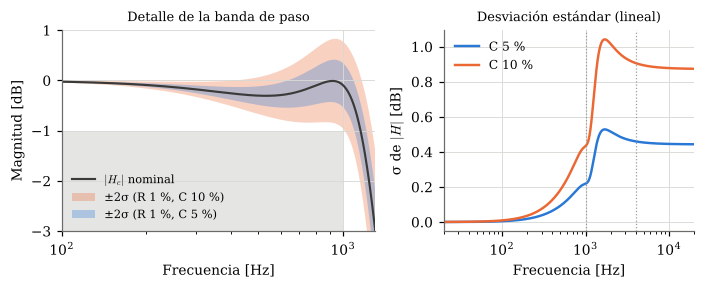

C ±5 %: σ(|H|) en 1 kHz = 0.219 dB; máximo en la banda de paso = 0.219 dB (en 999 Hz); en 4 kHz = 0.460 dB
C ±10 %: σ(|H|) en 1 kHz = 0.433 dB; máximo en la banda de paso = 0.433 dB (en 999 Hz); en 4 kHz = 0.906 dB


In [9]:
TOL = {'R': 0.01}
H0db = 20 * np.log10(np.abs(sp.lambdify(s, Hc.subs(VAL), 'numpy')(sj)))
K = 20 / np.log(10)
bandas = {}
for tolC in (0.05, 0.10):
    var = sum((SH[k_] * ((TOL['R'] if k_.startswith('R') else tolC) / np.sqrt(3)))**2 for k_ in SH)
    bandas[tolC] = K * np.sqrt(var)
fig, axs = plt.subplots(1, 2, figsize=(6.6, 2.7), gridspec_kw={'width_ratios': [1.25, 1]})
ax = axs[0]
ax.semilogx(f, H0db, color='#3a3a38', lw=1.4, label='$|H_c|$ nominal')
for tolC, col in [(0.10, NARANJA), (0.05, AZUL)]:
    sig = bandas[tolC]
    ax.fill_between(f, H0db - 2 * sig, H0db + 2 * sig, color=col, alpha=0.30, lw=0, label=f'±2σ (R 1 %, C {tolC*100:.0f} %)')
ax.fill_between([1, PL['fp']], -60, -PL['Ap'], color=GRIS, alpha=0.25, lw=0)
ax.set(xlim=(100, 1300), ylim=(-3, 1), xlabel='Frecuencia [Hz]', ylabel='Magnitud [dB]', title='Detalle de la banda de paso')
ax.title.set_fontsize(8.5); ax.legend(fontsize=7.5, loc='lower left')
ax = axs[1]
for tolC, col in [(0.05, AZUL), (0.10, NARANJA)]:
    ax.semilogx(f, bandas[tolC], color=col, label=f'C {tolC*100:.0f} %')
for fb in (PL['fp'], PL['fs']):
    ax.axvline(fb, color=GRIS, lw=0.8, ls=':')
ax.set(xlim=(20, 2e4), xlabel='Frecuencia [Hz]', ylabel='σ de $|H|$ [dB]', title='Desviación estándar (lineal)')
ax.title.set_fontsize(8.5); ax.legend(fontsize=8)
fig.tight_layout(); guardar(fig, 'fig_banda_dispersion'); plt.show()
for tolC, sig in bandas.items():
    print(f'C ±{tolC*100:.0f} %: σ(|H|) en 1 kHz = {sig[i1k]:.3f} dB; máximo en la banda de paso = {sig[f <= PL["fp"]].max():.3f} dB '
          f'(en {f[f <= PL["fp"]][np.argmax(sig[f <= PL["fp"]])]:.0f} Hz); en 4 kHz = {sig[i4k]:.3f} dB')

### 4.1 Predicción lineal de la dispersión de $f_r$, $f_0$ y $Q$ frente a Monte Carlo
Predicción de primer orden para variables independientes: $\left(\sigma_P/P\right)^2 \approx \sum_x \left(S^P_x\right)^2 \left(\sigma_x/x\right)^2$.
Se contrasta con un Monte Carlo sobre las expresiones exactas (uniforme, 100 000 muestras). El contraste con LTspice corresponde al Nivel II.

In [10]:
rng = np.random.default_rng(3)
M = 100000
filas = []
for tolC in (0.05, 0.10):
    tol_x = {Rs: 0.0, R0: 0.01, C0: tolC, R1: 0.01, R2: 0.01, C1: tolC, C2: tolC}
    muestras = {x: VAL[x] * (1 + tol_x[x] * rng.uniform(-1, 1, M)) for x in ELEM}
    fn = {p: sp.lambdify(ELEM, P, 'numpy') for p, P in PARAM.items()}
    for p, P in PARAM.items():
        nominal = float(P.subs(VAL))
        mc = fn[p](*[muestras[x] for x in ELEM])
        pred = np.sqrt(sum((float(SENS[p][x].subs(VAL)) * tol_x[x] / np.sqrt(3))**2 for x in ELEM))
        filas.append({'tol. C': f'±{tolC*100:.0f} %', 'parámetro': p, 'σ/P lineal [%]': 100 * pred,
                      'σ/P Monte Carlo [%]': 100 * np.std(mc) / nominal, 'sesgo MC [%]': 100 * (np.mean(mc) / nominal - 1)})
disp = pd.DataFrame(filas)
disp.round(3)

,tol. C,parámetro,σ/P lineal [%],σ/P Monte Carlo [%],sesgo MC [%]
0,±5 %,\omega_r,2.944,2.950,0.075
1,±5 %,\omega_0,2.082,2.091,0.066
2,±5 %,Q,2.043,2.043,0.021
3,±10 %,\omega_r,5.802,5.848,0.353
4,±10 %,\omega_0,4.103,4.117,0.260
5,±10 %,Q,4.083,4.097,0.074


## 5. LTspice
### 5.1 Netlists
Se generan netlists SPICE ejecutables en `ltspice/` (LTspice: *File → Open*, tipo `*.cir`; luego *Run*). Las resistencias en serie se modelan como
dos elementos y se agregan nodos intermedios (11, 31, 41); la numeración principal (1 a 6) es la del esquema.

| Archivo | AO | Análisis |
|---|---|---|
| `filtro_ideal_ac.cir` | VCVS de ganancia $10^6$ (ideal) | AC 10 Hz – 100 kHz |
| `filtro_lineal_ac.cir` | AO lineal de un polo (GBW 3 MHz, $A_0 = 2\cdot10^5$), **modelo pedagógico** | AC |
| `filtro_TL072_ac.cir` | **Modelo PSpice de TI del TL072** (`TL072.301`, SLOJ067), ±12 V | AC |
| `filtro_TL072_tran.cir` | TL072 | Transitorio: senoidal de 1 V eficaz a 200 Hz, 1 kHz y 4 kHz (`.step`) |
| `filtro_TL072_escalon.cir` | TL072 | Transitorio: escalón de 1 V |
| `filtro_TL072_gran_senal.cir` | TL072 | Transitorio: senoidal en la frecuencia de máximo nivel interno, 4, 8 y 11 V de pico (saturación) |

El modelo de TI **no viene con LTspice**: hay que descargar *TL072 PSpice Model* (SLOJ067) desde la página del TL072 en ti.com y copiar el archivo
del modelo (`TL072.301`) en la carpeta `ltspice/`. El subcircuito se llama `TL072` y sus nodos son: entrada no inversora, entrada inversora,
alimentación positiva, alimentación negativa y salida.

In [11]:
R0a, R0b = (SERIE['R0'] + [None])[:2]
def r_lineas(nombre, nodo_a, nodo_b, partes, nodo_medio):
    if len(partes) == 1:
        return [f'{nombre} {nodo_a} {nodo_b} {{{nombre}}}'], {nombre: partes[0]}
    return ([f'{nombre}a {nodo_a} {nodo_medio} {{{nombre}a}}', f'{nombre}b {nodo_medio} {nodo_b} {{{nombre}b}}'],
            {f'{nombre}a': partes[0], f'{nombre}b': partes[1]})

def spice_val(x):
    for suf, fac in [('Meg', 1e6), ('k', 1e3), ('', 1), ('m', 1e-3), ('u', 1e-6), ('n', 1e-9), ('p', 1e-12)]:
        if abs(x) >= fac * 0.9999:
            v = x / fac
            return (f'{v:.6g}{suf}')
    return f'{x:.6g}'

def red_pasiva():
    lineas, params = [], {'Rs': COMP['Rs'], 'C0': COMP['C0'], 'C1': COMP['C1'], 'C2': COMP['C2']}
    lineas.append('Rs in 1 {Rs}')
    for nombre, a, b, medio in [('R0', 1, 2, 11)]:
        l, p = r_lineas(nombre, a, b, SERIE['R0'], medio); lineas += l; params.update(p)
    lineas.append('C0 2 0 {C0}')
    l, p = r_lineas('R1', 3, 4, SERIE['R1'], 31); lineas += l; params.update(p)
    l, p = r_lineas('R2', 4, 5, SERIE['R2'], 41); lineas += l; params.update(p)
    lineas += ['C1 4 6 {C1}', 'C2 5 0 {C2}']
    return lineas, params

def netlist(titulo, ao, analisis, fuente, extra=()):
    lineas, params = red_pasiva()
    items = [f'{k}={spice_val(v)}' for k, v in params.items()]
    cab = [f'* {titulo}',
           '* TP Integrador SRA 2026 - Grupo 3 - LP Chebyshev I, orden 3',
           '* RC + seguidor (U1) y Sallen-Key k=1 (U2)',
           '* Generado por el notebook 03 desde resultados/componentes.json',
           '* Nodos: 1 gen., 2 U1+, 3 sal. U1, 4 nodo SK, 5 U2+, 6 salida',
           '.param ' + ' '.join(items[:5]), '.param ' + ' '.join(items[5:])]
    if ao == 'ideal':
        cuerpo = ['* AO ideal: VCVS de ganancia 1e6 (seguidores)', 'E1 3 0 2 3 1e6', 'E2 6 0 5 6 1e6']
    elif ao == 'lineal':
        cuerpo = ['* AO lineal de un polo (MODELO PEDAGOGICO, no comercial)', '* A(s) = A0/(1+s/wp), GBW = A0*fp = 3 MHz',
                  '* A0 = 2e5, polo dominante en GBW/A0 = 15 Hz',
                  'E1 3 0 2 3 Laplace=2e5/(1+s/(2*pi*15))', 'E2 6 0 5 6 Laplace=2e5/(1+s/(2*pi*15))']
    else:
        cuerpo = ['* Modelo TI TL072 (PSpice, SLOJ067). Nodos: IN+ IN- V+ V- OUT',
                  '.lib TL072.301', 'VCC vcc 0 12', 'VEE vee 0 -12',
                  'XU1 2 3 vcc vee 3 TL072', 'XU2 5 6 vcc vee 6 TL072']
    opciones = ['.options plotwinsize=0   ; sin compresion de formas de onda (todos los puntos en el .raw)']
    return '\n'.join(cab + [fuente] + lineas + cuerpo + list(analisis) + list(extra) + opciones + ['.end']) + '\n'

AC = ['.ac dec 200 10 100k',
      '.meas AC Amax MAX mag(V(6)) FROM 10 TO 1k', '.meas AC Amin MIN mag(V(6)) FROM 10 TO 1k',
      '.meas AC A1k FIND mag(V(6)) AT 1k', '.meas AC A4k FIND mag(V(6)) AT 4k',
      '.meas AC f3dB WHEN mag(V(6))=0.70795 FALL=1', '.meas AC N4max MAX mag(V(4))']
FUENTE_AC = 'V1 in 0 AC 1'
archivos = {
    'filtro_ideal_ac.cir': netlist('Filtro - AO ideal - analisis AC', 'ideal', AC, FUENTE_AC),
    'filtro_lineal_ac.cir': netlist('Filtro - AO lineal de un polo (pedagogico) - AC', 'lineal', AC, FUENTE_AC),
    'filtro_TL072_ac.cir': netlist('Filtro - TL072 (modelo TI) - analisis AC', 'tl072', AC, FUENTE_AC),
    'filtro_TL072_tran.cir': netlist(
        'Filtro - TL072 - senoidal 1 Vrms a 200 Hz, 1 kHz y 4 kHz', 'tl072',
        ['.param fin=1k Vp=1.41421', '.step param fin list 200 1k 4k', '.tran 0 30m 0 2u',
         '.meas TRAN Vin_pp PP V(in) FROM 20m TO 30m', '.meas TRAN Vout_pp PP V(6) FROM 20m TO 30m',
         '.meas TRAN Ganancia PARAM Vout_pp/Vin_pp', '.meas TRAN Vmax_U1 MAX V(3)', '.meas TRAN Vmax_U2 MAX V(6)'],
        'V1 in 0 SINE(0 {Vp} {fin})', ['.save V(in) V(2) V(3) V(4) V(6)']),
    'filtro_TL072_escalon.cir': netlist(
        'Filtro - TL072 - respuesta al escalon de 1 V', 'tl072',
        ['.tran 0 10m 0 1u', '.meas TRAN Vfinal AVG V(6) FROM 8m TO 10m', '.meas TRAN Vmax MAX V(6) FROM 1m TO 8m',
         '.meas TRAN Sobrepico PARAM 100*(Vmax-Vfinal)/Vfinal'],
        'V1 in 0 PULSE(0 1 1m 100n 100n 20m 40m)', ['.save V(in) V(3) V(6)']),
    'filtro_TL072_gran_senal.cir': netlist(
        'Filtro - TL072 - gran senal: 4, 8 y 11 V pico a 936 Hz', 'tl072',
        ['.param fin=936 Vp=4', '.step param Vp list 4 8 11', '.tran 0 20m 0 2u',
         '.meas TRAN Vmax_U1 MAX V(3) FROM 10m TO 20m', '.meas TRAN Vmax_U2 MAX V(6) FROM 10m TO 20m',
         '.meas TRAN Vmin_U2 MIN V(6) FROM 10m TO 20m'],
        'V1 in 0 SINE(0 {Vp} {fin})', ['.save V(in) V(3) V(4) V(6)']),
}
for nombre, texto in archivos.items():
    (LTS / nombre).write_text(texto, encoding='ascii', errors='replace')
print(archivos['filtro_TL072_ac.cir'])

* Filtro - TL072 (modelo TI) - analisis AC
* TP Integrador SRA 2026 - Grupo 3 - LP Chebyshev I, orden 3
* RC + seguidor (U1) y Sallen-Key k=1 (U2)
* Generado por el notebook 03 desde resultados/componentes.json
* Nodos: 1 gen., 2 U1+, 3 sal. U1, 4 nodo SK, 5 U2+, 6 salida
.param Rs=50 C0=10n C1=47n C2=4.7n R0a=20k
.param R0b=560 R1a=7.5k R1b=3.3k R2a=6.8k R2b=560
V1 in 0 AC 1
Rs in 1 {Rs}
R0a 1 11 {R0a}
R0b 11 2 {R0b}
C0 2 0 {C0}
R1a 3 31 {R1a}
R1b 31 4 {R1b}
R2a 4 41 {R2a}
R2b 41 5 {R2b}
C1 4 6 {C1}
C2 5 0 {C2}
* Modelo TI TL072 (PSpice, SLOJ067). Nodos: IN+ IN- V+ V- OUT
.lib TL072.301
VCC vcc 0 12
VEE vee 0 -12
XU1 2 3 vcc vee 3 TL072
XU2 5 6 vcc vee 6 TL072
.ac dec 200 10 100k
.meas AC Amax MAX mag(V(6)) FROM 10 TO 1k
.meas AC Amin MIN mag(V(6)) FROM 10 TO 1k
.meas AC A1k FIND mag(V(6)) AT 1k
.meas AC A4k FIND mag(V(6)) AT 4k
.meas AC f3dB WHEN mag(V(6))=0.70795 FALL=1
.meas AC N4max MAX mag(V(4))
.options plotwinsize=0   ; sin compresion de formas de onda (todos los puntos en el .

### 5.2 Verificación de los netlists con un solver nodal propio
Antes de correr LTspice se verifica que los netlists representen el circuito analizado: un solver de análisis nodal modificado (MNA) en NumPy lee
el netlist (R, C, fuentes de tensión, VCVS y `.param`), resuelve el análisis AC y se compara con $H_c(s)$ de SymPy. Esto detecta errores de nodos o de
valores sin depender de LTspice.

In [12]:
SUF = {'meg': 1e6, 'k': 1e3, 'm': 1e-3, 'u': 1e-6, 'µ': 1e-6, 'n': 1e-9, 'p': 1e-12, 'g': 1e9, 'f': 1e-15}
def valor_spice(t, params):
    t = t.strip().strip('{}')
    if t in params:
        return params[t]
    m = re.fullmatch(r'([-+]?[\d.]+(?:e[-+]?\d+)?)([a-zA-Zµ]*)', t)
    if m:
        suf = m.group(2).lower()
        fac = SUF['meg'] if suf.startswith('meg') else SUF.get(suf[:1], 1.0) if suf else 1.0
        return float(m.group(1)) * fac
    return float(eval(t, {'__builtins__': {}}, dict(params)))

def mna_ac(texto, f, salida='6'):
    params, elems = {}, []
    for linea in texto.splitlines():
        l = linea.strip()
        if not l or l.startswith('*'):
            continue
        if l.lower().startswith('.param'):
            for k_, v in re.findall(r'(\w+)=(\S+)', l):
                params[k_] = valor_spice(v, params)
            continue
        if l.startswith('.'):
            continue
        elems.append(l.split())
    nodos = sorted({n for e in elems for n in (e[1:3] if e[0][0] in 'RCV' else e[1:5]) if n != '0'})
    idx = {n: i for i, n in enumerate(nodos)}
    fuentes = [e for e in elems if e[0][0] in 'VE']
    N, Mv = len(nodos), len(fuentes)
    out = np.zeros(len(f), complex)
    for k_, fk in enumerate(f):
        sk = 2j * np.pi * fk
        A = np.zeros((N + Mv, N + Mv), complex); b = np.zeros(N + Mv, complex)
        def estampa(a, c, y):
            for (p_, q_, sg) in [(a, a, 1), (c, c, 1), (a, c, -1), (c, a, -1)]:
                if p_ != '0' and q_ != '0':
                    A[idx[p_], idx[q_]] += sg * y
        j = 0
        for e in elems:
            t = e[0][0].upper()
            if t == 'R':
                estampa(e[1], e[2], 1 / valor_spice(e[3], params))
            elif t == 'C':
                estampa(e[1], e[2], sk * valor_spice(e[3], params))
            elif t in 'VE':
                fila = N + j
                for n_, sg in [(e[1], 1), (e[2], -1)]:
                    if n_ != '0':
                        A[idx[n_], fila] += sg; A[fila, idx[n_]] += sg
                if t == 'V':
                    b[fila] = 1.0 if 'AC' in [x.upper() for x in e] else 0.0
                else:
                    g = valor_spice(e[5], params)
                    for n_, sg in [(e[3], 1), (e[4], -1)]:
                        if n_ != '0':
                            A[fila, idx[n_]] -= sg * g
                j += 1
        x = np.linalg.solve(A, b)
        out[k_] = x[idx[salida]]
    return out

fv = np.geomspace(10, 1e5, 400)
H_mna = mna_ac(archivos['filtro_ideal_ac.cir'], fv)
H_sym = sp.lambdify(s, Hc.subs(VAL), 'numpy')(2j * np.pi * fv)
err_mna = np.max(np.abs(H_mna / H_sym - 1))
print(f'Netlist ideal vs H_c simbólica: error relativo máximo = {err_mna:.2e}  (VCVS de ganancia 1e6: se espera un error del orden de 1/A)')

Netlist ideal vs H_c simbólica: error relativo máximo = 7.94e-06  (VCVS de ganancia 1e6: se espera un error del orden de 1/A)


### 5.3 Resultados de LTspice
Después de correr los netlists en LTspice, copiar a `ltspice/resultados/` los archivos `.raw` y `.log` de cada simulación (LTspice los crea junto al
`.cir`). Las celdas siguientes los leen con `spicelib`, superponen las respuestas y comparan: **respuesta ideal** ($H_d$, SciPy), **respuesta
circuital ideal** ($H_c$, SymPy y LTspice con AO ideal) y **circuito con el modelo comercial** (LTspice con TL072).

Resultados AC de LTspice disponibles: ['ideal', 'lineal', 'TL072']


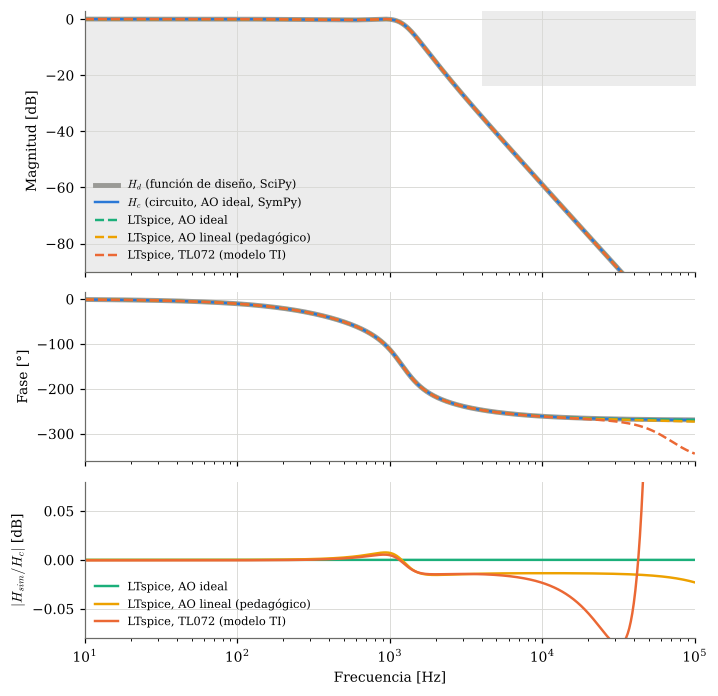

,simulación,máx |Δ| hasta 4 kHz [dB],A(1 kHz) [dB],A(4 kHz) [dB]
0,"LTspice, AO ideal",0.0001,0.0940,34.7143
1,"LTspice, AO lineal (pedagógico)",0.0154,0.0868,34.7283
2,"LTspice, TL072 (modelo TI)",0.0148,0.0891,34.7289


In [13]:
try:
    from spicelib import RawRead
except ImportError:
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'spicelib'], check=True)
    from spicelib import RawRead

def leer_ac(nombre):
    """Devuelve (f, V(6)) de un .raw AC de LTspice, o None si no existe."""
    for carpeta in (LTS / 'resultados', LTS):
        p = carpeta / nombre
        if p.exists():
            raw = RawRead(str(p))
            fr = np.real(raw.get_trace('frequency').get_wave())
            v6 = raw.get_trace('V(6)').get_wave()
            return np.abs(fr), np.asarray(v6)
    return None

def leer_meas(nombre):
    """Lee las líneas '.meas' de un .log de LTspice."""
    for carpeta in (LTS / 'resultados', LTS):
        p = carpeta / nombre
        if p.exists():
            b = p.read_bytes()
            txt = b.decode('utf-16-le', errors='ignore') if b.count(b'\x00') > len(b) // 4 else b.decode('utf-8', errors='ignore')
            return [l.strip() for l in txt.splitlines() if re.match(r'^\s*\w+\s*[:=]', l)]
    return None

ac = {k_: leer_ac(f'filtro_{k_}_ac.raw') for k_ in ('ideal', 'lineal', 'TL072')}
disponibles = [k_ for k_, v in ac.items() if v is not None]
print('Resultados AC de LTspice disponibles:', disponibles or 'ninguno todavía (correr los .cir en LTspice)')

fz = np.geomspace(10, 1e5, 3000)
Hd = resp(ZPK_D, fz); Hci = sp.lambdify(s, Hc.subs(VAL), 'numpy')(2j * np.pi * fz)
fig, axs = plt.subplots(3, 1, figsize=(6.6, 6.4), sharex=True, gridspec_kw={'height_ratios': [2, 1.3, 1.2]})
axs[0].semilogx(fz, 20 * np.log10(np.abs(Hd)), color=GRIS, lw=3.2, label='$H_d$ (función de diseño, SciPy)')
axs[0].semilogx(fz, 20 * np.log10(np.abs(Hci)), color=AZUL, label='$H_c$ (circuito, AO ideal, SymPy)')
axs[1].semilogx(fz, np.degrees(np.unwrap(np.angle(Hd))), color=GRIS, lw=3.2)
axs[1].semilogx(fz, np.degrees(np.unwrap(np.angle(Hci))), color=AZUL)
colores = {'ideal': VERDE, 'lineal': AMARILLO, 'TL072': NARANJA}
etiquetas = {'ideal': 'LTspice, AO ideal', 'lineal': 'LTspice, AO lineal (pedagógico)', 'TL072': 'LTspice, TL072 (modelo TI)'}
resumen_lt = []
for k_ in disponibles:
    fr_, v_ = ac[k_]
    axs[0].semilogx(fr_, 20 * np.log10(np.abs(v_)), color=colores[k_], ls='--', label=etiquetas[k_])
    axs[1].semilogx(fr_, np.degrees(np.unwrap(np.angle(v_))), color=colores[k_], ls='--')
    ref = sp.lambdify(s, Hc.subs(VAL), 'numpy')(2j * np.pi * fr_)
    axs[2].semilogx(fr_, 20 * np.log10(np.abs(v_ / ref)), color=colores[k_], label=etiquetas[k_])
    resumen_lt.append({'simulación': etiquetas[k_],
                       'máx |Δ| hasta 4 kHz [dB]': np.max(np.abs(20 * np.log10(np.abs(v_ / ref))[fr_ <= 4000])),
                       'A(1 kHz) [dB]': -20 * np.log10(np.abs(np.interp(1000, fr_, np.abs(v_)))),
                       'A(4 kHz) [dB]': -20 * np.log10(np.abs(np.interp(4000, fr_, np.abs(v_))))})
axs[0].fill_between([1, PL['fp']], -90, -PL['Ap'], color=GRIS, alpha=0.18, lw=0)
axs[0].fill_between([PL['fs'], 1e6], -PL['As'], 5, color=GRIS, alpha=0.18, lw=0)
axs[0].set(ylim=(-90, 3), ylabel='Magnitud [dB]'); axs[0].legend(fontsize=7.5, loc='lower left')
axs[1].set(ylabel='Fase [°]')
axs[2].set(xlim=(10, 1e5), ylim=(-0.08, 0.08), xlabel='Frecuencia [Hz]', ylabel='$|H_{sim}/H_c|$ [dB]')
if disponibles:
    axs[2].legend(fontsize=7.5, loc='lower left')
else:
    axs[2].text(0.5, 0.5, 'pendiente: resultados de LTspice', transform=axs[2].transAxes, ha='center', color=GRIS)
fig.tight_layout(); guardar(fig, 'fig_ltspice_ac'); plt.show()
pd.DataFrame(resumen_lt).round(4) if resumen_lt else print('Sin resultados de LTspice todavía.')

In [14]:
for nombre in ['filtro_ideal_ac.log', 'filtro_lineal_ac.log', 'filtro_TL072_ac.log', 'filtro_TL072_tran.log',
               'filtro_TL072_escalon.log', 'filtro_TL072_gran_senal.log']:
    m = leer_meas(nombre)
    print(f'--- {nombre}:', 'no disponible' if m is None else '')
    for l in (m or []):
        print('   ', l)

--- filtro_ideal_ac.log: 
    Circuit: C:\Users\maria\Desktop\Filtros_SRA_2026_etapa3\Filtros_SRA_2026\ltspice\filtro_ideal_ac.cir
    solver = Normal
    tnom = 27
    temp = 27
    method = trap
    C:\Users\maria\Desktop\Filtros_SRA_2026_etapa3\Filtros_SRA_2026\ltspice\filtro_ideal_ac.cir
    amax: MAX(mag(V(6)))=(-0.000268388460769dB,0°) FROM 10 TO 1000
    amin: MIN(mag(V(6)))=(-0.305257849017dB,0°) FROM 10 TO 1000
    a1k: mag(V(6))=(-0.0939554591143dB,0°) at 1000
    a4k: mag(V(6))=(-34.7142794448dB,0°) at 4000
    f3db: mag(V(6))=0.70795 AT 1302.49499736
    n4max: MAX(mag(V(4)))=(0.163450772379dB,0°) FROM 10 TO 100000
--- filtro_lineal_ac.log: 
    Circuit: C:\Users\maria\Desktop\Filtros_SRA_2026_etapa3\Filtros_SRA_2026\ltspice\filtro_lineal_ac.cir
    solver = Normal
    tnom = 27
    temp = 27
    method = trap
    C:\Users\maria\Desktop\Filtros_SRA_2026_etapa3\Filtros_SRA_2026\ltspice\filtro_lineal_ac.cir
    amax: MAX(mag(V(6)))=(-0.000336957970976dB,0°) FROM 10 TO 1000
  

### 5.4 Alta frecuencia: fuga del Sallen–Key de ganancia unitaria
A frecuencias muy por encima de $f_0$, $C_1$ y $C_2$ son casi cortocircuitos: el nodo 4 queda unido a la salida y la corriente que entra por $R_1$
desde U1 se inyecta directamente en la salida de U2. Con un AO ideal la impedancia de salida es nula y esa corriente no produce tensión; con un AO
real, $Z_o(j\omega) \approx r_o/(1+A(j\omega))$ crece con la frecuencia y aparece un camino directo $V_o \approx V_3\,Z_o/R_1$ que **limita la
atenuación** en la banda de rechazo lejana. Se cuantifica con el modelo de TI ($r_o \approx 300\ \Omega$ entre RO1 y RO2 del macromodelo).

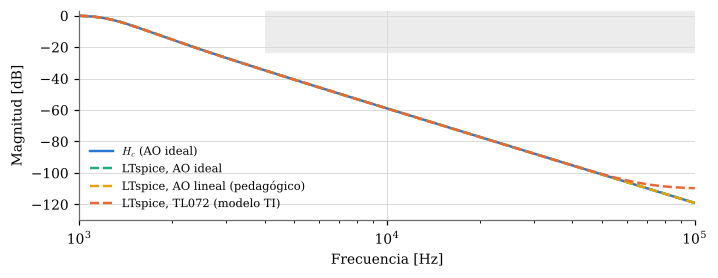

Estimación a 100 kHz: |V3/Vi| = 0.0077, |Zo| ≈ 10.0 Ω -> |Vo/Vi| ≈ -102.9 dB


,simulación,hasta [Hz],máx |Δ| [dB],máx |Δfase| [°]
0,"LTspice, AO ideal",4000.0,0.0001,0.0002
1,"LTspice, AO ideal",20000.0,0.0001,0.0002
2,"LTspice, AO ideal",100000.0,0.0001,0.0002
3,"LTspice, AO lineal (pedagógico)",4000.0,0.0154,0.1885
4,"LTspice, AO lineal (pedagógico)",20000.0,0.0154,0.7649
5,"LTspice, AO lineal (pedagógico)",100000.0,0.0230,3.8160
6,"LTspice, TL072 (modelo TI)",4000.0,0.0148,0.1647
7,"LTspice, TL072 (modelo TI)",20000.0,0.0543,1.9601
8,"LTspice, TL072 (modelo TI)",100000.0,9.3594,75.3008


In [15]:
alta = []
fig, ax = plt.subplots(figsize=(6.6, 2.6))
fh = np.geomspace(1e3, 1e5, 2000)
ax.semilogx(fh, 20 * np.log10(np.abs(sp.lambdify(s, Hc.subs(VAL), 'numpy')(2j * np.pi * fh))), color=AZUL, label='$H_c$ (AO ideal)')
for k_ in disponibles:
    fr_, v_ = ac[k_]
    m_ = fr_ >= 1e3
    ax.semilogx(fr_[m_], 20 * np.log10(np.abs(v_[m_])), color=colores[k_], ls='--', label=etiquetas[k_])
    ref = sp.lambdify(s, Hc.subs(VAL), 'numpy')(2j * np.pi * fr_)
    d_ = 20 * np.log10(np.abs(v_ / ref))
    for flim in (4e3, 2e4, 1e5):
        alta.append({'simulación': etiquetas[k_], 'hasta [Hz]': flim, 'máx |Δ| [dB]': np.max(np.abs(d_[fr_ <= flim])),
                     'máx |Δfase| [°]': np.degrees(np.max(np.abs(np.angle(v_[fr_ <= flim] / ref[fr_ <= flim]))))})
ax.fill_between([PL['fs'], 1e6], -PL['As'], 5, color=GRIS, alpha=0.18, lw=0)
ax.set(xlim=(1e3, 1e5), ylim=(-130, 3), xlabel='Frecuencia [Hz]', ylabel='Magnitud [dB]'); ax.legend(fontsize=7.5, loc='lower left')
fig.tight_layout(); guardar(fig, 'fig_ltspice_altafrec'); plt.show()
alta = pd.DataFrame(alta)
# Estimación de la fuga a 100 kHz con el modelo de un polo de Zo (r_o = 300 Ω, GBW = 3 MHz)
f_e = 1e5
V3_e = abs(1 / (1 + 2j * np.pi * f_e / P0[KWR]))
Zo_e = abs(300 / (1 + 3e6 / (1j * f_e)))
print(f'Estimación a 100 kHz: |V3/Vi| = {V3_e:.4f}, |Zo| ≈ {Zo_e:.1f} Ω -> |Vo/Vi| ≈ {20*np.log10(V3_e*Zo_e/COMP["R1"]):.1f} dB')
alta.round(4) if len(alta) else print('Sin datos AC de LTspice.')

### 5.5 Transitorio senoidal (TL072)
Para cada frecuencia se ajusta por mínimos cuadrados un seno de frecuencia conocida ($a\sin\omega t + b\cos\omega t + c$) a la entrada y a la salida en
régimen permanente (20–30 ms), y se obtienen ganancia y desfase. Se comparan con $H_c(j\omega)$.

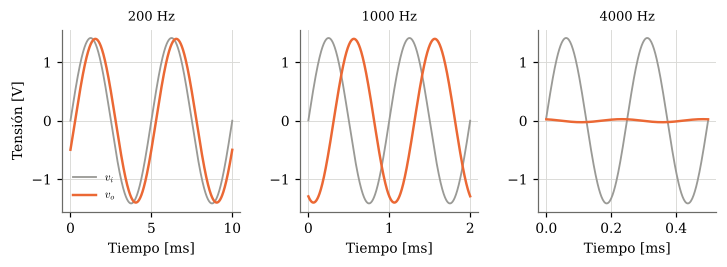

,f [Hz],puntos en la ventana,ganancia LTspice [dB],ganancia H_c [dB],fase LTspice [°],fase H_c [°]
0,200.0,5001,-0.0905,-0.0902,-20.8234,-20.8153
1,1000.0,5001,-0.0892,-0.0939,-112.6659,-112.5504
2,4000.0,5001,-34.7364,-34.7160,112.7610,112.9279


In [16]:
def leer_tran(nombre):
    for carpeta in (LTS / 'resultados', LTS):
        p = carpeta / nombre
        if p.exists():
            raw = RawRead(str(p))
            pasos = list(raw.get_steps())
            out = []
            for st in pasos:
                t = np.real(raw.get_trace('time').get_wave(st))
                t = np.abs(t)
                d = {n: np.real(raw.get_trace(n).get_wave(st)) for n in raw.get_trace_names() if n != 'time'}
                out.append((t, d))
            return out
    return None

def ajuste_seno(t, y, fk):
    w = 2 * np.pi * fk
    A = np.column_stack([np.sin(w * t), np.cos(w * t), np.ones_like(t)])
    (a, b, c), *_ = np.linalg.lstsq(A, y, rcond=None)
    return np.hypot(a, b), np.arctan2(b, a), c

tran = leer_tran('filtro_TL072_tran.raw')
F_TRAN = [200.0, 1000.0, 4000.0]
filas_tr = []
if tran:
    fig, axs = plt.subplots(1, 3, figsize=(6.8, 2.5))
    Hc_f = sp.lambdify(s, Hc.subs(VAL), 'numpy')
    for ax, (t, dd), fk in zip(axs, tran, F_TRAN):
        m_ = (t >= 20e-3) & (t <= 30e-3)
        ai, phi_i, _ = ajuste_seno(t[m_], dd['V(in)'][m_], fk)
        ao, phi_o, _ = ajuste_seno(t[m_], dd['V(6)'][m_], fk)
        Hk = Hc_f(2j * np.pi * fk)
        fase = np.degrees(np.angle(np.exp(1j * (phi_o - phi_i))))
        filas_tr.append({'f [Hz]': fk, 'puntos en la ventana': int(m_.sum()), 'ganancia LTspice [dB]': 20 * np.log10(ao / ai),
                         'ganancia H_c [dB]': 20 * np.log10(abs(Hk)), 'fase LTspice [°]': fase, 'fase H_c [°]': np.degrees(np.angle(Hk))})
        T = 1 / fk
        mv = (t >= 30e-3 - 2 * T)
        ax.plot(1e3 * (t[mv] - t[mv][0]), dd['V(in)'][mv], color=GRIS, lw=1.2, label='$v_i$')
        ax.plot(1e3 * (t[mv] - t[mv][0]), dd['V(6)'][mv], color=NARANJA, label='$v_o$')
        ax.set(title=f'{fk:g} Hz', xlabel='Tiempo [ms]'); ax.title.set_fontsize(8.5)
    axs[0].set_ylabel('Tensión [V]'); axs[0].legend(fontsize=7.5, loc='lower left')
    fig.tight_layout(); guardar(fig, 'fig_ltspice_tran'); plt.show()
tab_tr = pd.DataFrame(filas_tr)
tab_tr.round(4) if len(tab_tr) else print('Sin datos de transitorio.')

### 5.6 Respuesta al escalón y ensayo de gran señal (TL072)

Sobrepico de H_c (Python): 9.716 %
Escalón LTspice: 10025 puntos guardados en el .raw


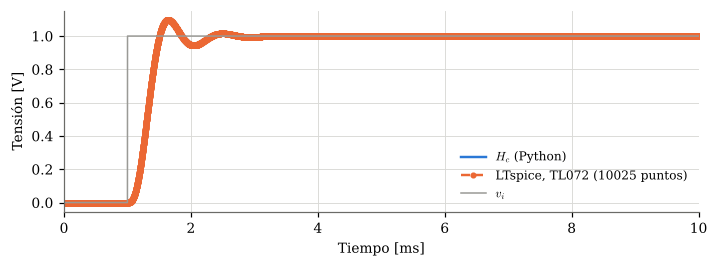

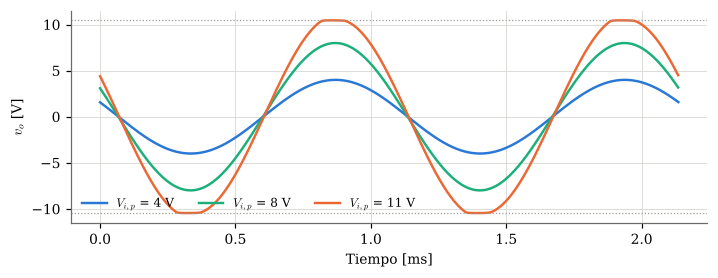

ideal_ac {'amax': [-0.000268388460769], 'amin': [-0.305257849017], 'a1k': [-0.0939554591143], 'a4k': [-34.7142794448], 'f3db': [1302.49499736], 'n4max': [0.163450772379]}
lineal_ac {'amax': [-0.000336957970976], 'amin': [-0.302450836235], 'a1k': [-0.0867711958841], 'a4k': [-34.7283748351], 'f3db': [1302.14786217], 'n4max': [0.171103541307]}
TL072_ac {'amax': [-0.00080326826349], 'amin': [-0.303432895637], 'a1k': [-0.0891374456838], 'a4k': [-34.7289481185], 'f3db': [1302.08057795], 'n4max': [0.169095825897]}
TL072_tran {'options': [0.0], 'vin_pp': [2.82841920853, 2.82839846611, 2.82801663876], 'vout_pp': [2.79910445213, 2.79952609539, 0.0518418252468], 'ganancia': [0.989635639475, 0.989791972006, 0.0183315135195], 'vmax_u1': [1.36930584908, 0.968554973602, 0.418448925018], 'vmax_u2': [1.39957237244, 1.39994299412, 0.197998896241]}
TL072_escalon {'options': [0.0], 'vfinal': [0.999956488609], 'vmax': [1.09740352631], 'sobrepico': [9.74512779373]}
TL072_gran_senal {'options': [0.0], 'vmax_

In [17]:
esc = leer_tran('filtro_TL072_escalon.raw')
num_c, den_c = sp.fraction(sp.together(Hc.subs(VAL)))
sys_c = signal.lti([float(c_) for c_ in sp.Poly(num_c, s).all_coeffs()], [float(c_) for c_ in sp.Poly(den_c, s).all_coeffs()])
t_py, y_py = signal.step(sys_c, T=np.linspace(0, 9e-3, 90001))
sobre_py = 100 * (y_py.max() - y_py[-1]) / y_py[-1]
print(f'Sobrepico de H_c (Python): {sobre_py:.3f} %')
if esc:
    t, dd = esc[0]
    print(f'Escalón LTspice: {len(t)} puntos guardados en el .raw')
    fig, ax = plt.subplots(figsize=(6.6, 2.5))
    ax.plot(1e3 * t_py + 1.0, y_py, color=AZUL, label='$H_c$ (Python)')
    ax.plot(1e3 * t, dd['V(6)'], color=NARANJA, ls='--', marker='o', ms=3, label=f'LTspice, TL072 ({len(t)} puntos)')
    ax.plot(1e3 * t, dd['V(in)'], color=GRIS, lw=1.0, label='$v_i$')
    ax.set(xlim=(0, 10), xlabel='Tiempo [ms]', ylabel='Tensión [V]'); ax.legend(fontsize=8, loc='lower right')
    fig.tight_layout(); guardar(fig, 'fig_ltspice_escalon'); plt.show()

gs = leer_tran('filtro_TL072_gran_senal.raw')
VP_GS = [4.0, 8.0, 11.0]
if gs:
    fig, ax = plt.subplots(figsize=(6.6, 2.6))
    for (t, dd), vp, col in zip(gs, VP_GS, [AZUL, VERDE, NARANJA]):
        m_ = t >= 20e-3 - 2 / 936
        ax.plot(1e3 * (t[m_] - t[m_][0]), dd['V(6)'][m_], color=col, label=f'$V_{{i,p}}$ = {vp:g} V')
    for y_ in (10.45, -10.45):
        ax.axhline(y_, color=GRIS, lw=0.8, ls=':')
    ax.set(xlabel='Tiempo [ms]', ylabel='$v_o$ [V]'); ax.legend(fontsize=8, loc='lower left', ncol=3)
    fig.tight_layout(); guardar(fig, 'fig_ltspice_gran_senal'); plt.show()

def leer_meas_tabla(nombre):
    """Devuelve {medición: [valores]} de un .log de LTspice (con o sin .step)."""
    for carpeta in (LTS / 'resultados', LTS):
        p = carpeta / nombre
        if not p.exists():
            continue
        b = p.read_bytes()
        txt = b.decode('utf-16-le', errors='ignore') if b.count(b'\x00') > len(b) // 4 else b.decode('utf-8', errors='ignore')
        res, actual = {}, None
        for l in txt.splitlines():
            l = l.strip()
            m = re.match(r'^Measurement:\s*(\w+)', l)
            if m:
                actual = m.group(1).lower(); res[actual] = []; continue
            if actual and re.match(r'^\d+\s', l):
                res[actual].append(float(l.split()[1])); continue
            m_at = re.match(r'^(\w+):.*\bAT\s+([-+\d.eE]+)', l)
            if m_at and 'WHEN' not in l.upper() and '=' in l and l.upper().count(' AT ') and 'mag(' in l and l.split('=')[1].strip().split()[0].replace('.', '', 1).isdigit():
                res[m_at.group(1).lower()] = [float(m_at.group(2))]; actual = None; continue
            m = re.match(r'^(\w+):.*?=\s*\(?([-+\d.eE]+)', l)
            if m:
                res[m.group(1).lower()] = [float(m.group(2))]; actual = None
        return res
    return None

MEAS = {k_: leer_meas_tabla(f'filtro_{k_}.log') for k_ in ['ideal_ac', 'lineal_ac', 'TL072_ac', 'TL072_tran', 'TL072_escalon', 'TL072_gran_senal']}
for k_, v in MEAS.items():
    print(k_, v)

## 6. Exportación para el informe

In [18]:
NOMP = {KWR: KWR, KW0: KW0, 'Q': 'Q'}
OHM, MU, FIN = r'$\Omega$', r'$\mu$', r'\\'
COL_WR, COL_W0 = 'S^' + KWR, 'S^' + KW0
lineas = [r'\begin{tabular}{@{}lrccc@{}}', r'\toprule',
          r'Elemento & Valor & $S^{\omega_r}_x$ & $S^{\omega_0}_x$ & $S^{Q}_x$ \\', r'\midrule']
for _, r in tab_s.iterrows():
    el = r.elemento
    el_tex = f'${el[0]}_{{{el[2:]}}}$' if '_' in el else el
    valor_tex = r.valor.replace('Ω', OHM).replace('µ', MU)
    s_wr, s_w0, s_q = num(r[COL_WR], 4), num(r[COL_W0], 4), num(r['S^Q'], 4)
    lineas.append(f"{el_tex} & {valor_tex} & {s_wr} & {s_w0} & {s_q} " + FIN)
    if el == 'C_2':
        lineas.append(r'\midrule')
lineas += [r'\bottomrule', r'\end{tabular}']
(RES / 'tab_sensibilidades.tex').write_text('\n'.join(lineas), encoding='utf-8')

lineas = [r'\begin{tabular}{@{}llccccc@{}}', r'\toprule',
          r'Elemento & Parámetro & $S$ simbólica & $S$ ($+1\,\%$) & $S$ ($-1\,\%$) & $S$ central & $|S_{\mathrm{central}} - S|$ \\', r'\midrule']
for _, r in val_fd[val_fd['S simbólica'].abs() > 1e-12].iterrows():
    el_tex = f'${r.elemento[0]}_{{{r.elemento[2:]}}}$'
    lineas.append(f"{el_tex} & ${NOMP[r['parámetro']]}$ & {num(r['S simbólica'], 4)} & {num(r['S (+1 %)'], 4)} & {num(r['S (−1 %)'], 4)} & "
                  f"{num(r['S central'], 4)} & {r['error central']:.1e} \\\\".replace('e-0', 'e-'))
lineas += [r'\bottomrule', r'\end{tabular}']
t = '\n'.join(lineas)
t = re.sub(r'(\d)\.(\d)e-(\d+)', lambda m_: f'\\num{{{m_.group(1)}.{m_.group(2)}e-{m_.group(3)}}}', t)
(RES / 'tab_validacion_sens.tex').write_text(t, encoding='utf-8')

lineas = [r'\begin{tabular}{@{}llccc@{}}', r'\toprule',
          r'Tolerancia de $C$ & Parámetro & $\sigma/P$ lineal [\%] & $\sigma/P$ Monte Carlo [\%] & Sesgo MC [\%] \\', r'\midrule']
for _, r in disp.iterrows():
    tol_txt = r['tol. C'].replace('±', r'$\pm$').replace('%', r'\%')
    lineas.append(f"{tol_txt} & ${NOMP[r['parámetro']]}$ & {num(r['σ/P lineal [%]'], 3)} & {num(r['σ/P Monte Carlo [%]'], 3)} & {num(r['sesgo MC [%]'], 3)} \\\\")
lineas += [r'\bottomrule', r'\end{tabular}']
(RES / 'tab_dispersion_lineal.tex').write_text('\n'.join(lineas), encoding='utf-8')

# Tablas de LTspice (si hay resultados)
if MEAS.get('TL072_ac'):
    Hc_n = sp.lambdify(s, Hc.subs(VAL), 'numpy')
    fgrid = np.geomspace(10, 1000, 20001)
    ref_vals = {'amin': -(-20 * np.log10(np.abs(Hc_n(2j * np.pi * np.append(fgrid, 1000.0))))).max(),
                'a1k': 20 * np.log10(abs(Hc_n(2j * np.pi * 1000.0))), 'a4k': 20 * np.log10(abs(Hc_n(2j * np.pi * 4000.0))),
                'f3db': float(__import__('scipy.optimize', fromlist=['brentq']).brentq(lambda x: abs(Hc_n(2j * np.pi * x)) - 0.70795, 1000, 3000)),
                'n4max': 20 * np.log10(np.max(np.abs(sp.lambdify(s, sp.simplify(sol[V4_] / Vi).subs(VAL), 'numpy')(2j * np.pi * np.geomspace(10, 1e5, 20000)))))}
    nombres = [('amin', r'$-A_{p,\max}$ en \qtyrange{10}{1000}{\hertz} [dB]', 3), ('a1k', r'$|H(\qty{1}{\kilo\hertz})|$ [dB]', 3),
               ('a4k', r'$|H(\qty{4}{\kilo\hertz})|$ [dB]', 2), ('f3db', r'Frecuencia de \qty{-3}{\decibel} [Hz]', 1),
               ('n4max', r'$\max|V_4/V_i|$ [dB]', 3)]
    lineas = [r'\begin{tabular}{@{}lcccc@{}}', r'\toprule', r'Magnitud & Python ($H_c$) & LTspice, AO ideal & LTspice, AO lineal & LTspice, TL072 \\', r'\midrule']
    for clave, txt, nd in nombres:
        ref_ = ref_vals[clave]
        celdas = [num(ref_, nd) if ref_ is not None else '---'] + [num(MEAS[k_][clave][0], nd) if MEAS.get(k_) and clave in MEAS[k_] else '---'
                                                                  for k_ in ('ideal_ac', 'lineal_ac', 'TL072_ac')]
        lineas.append(txt + ' & ' + ' & '.join(celdas) + r' \\')
    lineas += [r'\bottomrule', r'\end{tabular}']
    (RES / 'tab_ltspice_ac.tex').write_text('\n'.join(lineas), encoding='utf-8')
if len(tab_tr):
    lineas = [r'\begin{tabular}{@{}lcccccc@{}}', r'\toprule',
              r'$f$ [Hz] & Ganancia LTspice [dB] & Ganancia $H_c$ [dB] & $\Delta$ [dB] & Fase LTspice [°] & Fase $H_c$ [°] & $\Delta$ [°] \\', r'\midrule']
    for _, r in tab_tr.iterrows():
        lineas.append(f"{r['f [Hz]']:.0f} & {num(r['ganancia LTspice [dB]'], 3)} & {num(r['ganancia H_c [dB]'], 3)} & "
                      f"{num(r['ganancia LTspice [dB]'] - r['ganancia H_c [dB]'], 3)} & {num(r['fase LTspice [°]'], 2)} & "
                      f"{num(r['fase H_c [°]'], 2)} & {num(r['fase LTspice [°]'] - r['fase H_c [°]'], 2)} " + r'\\')
    lineas += [r'\bottomrule', r'\end{tabular}']
    (RES / 'tab_ltspice_tran.tex').write_text('\n'.join(lineas).replace('°', r'$^\circ$'), encoding='utf-8')

VAL3 = {
    'ErrMNA': f'{err_mna:.0e}',
    'MaxErrCentral': f"{val_fd['error central'].max():.0e}",
    'SQGBW': f"{gbw_tab.loc[gbw_tab['parámetro']=='Q', 'S^P_GBW'].values[0]:.1e}",
    'DQGBW': round(float(gbw_tab.loc[gbw_tab['parámetro']=='Q', 'desvío por GBW finito [%]'].values[0]), 3),
    'DfoGBW': round(float(gbw_tab.loc[gbw_tab['parámetro']==KW0, 'desvío por GBW finito [%]'].values[0]), 3),
    'SigCincoPaso': round(float(bandas[0.05][f <= PL['fp']].max()), 2),
    'SigDiezPaso': round(float(bandas[0.10][f <= PL['fp']].max()), 2),
    'SigCincoMil': round(float(bandas[0.05][i1k]), 2), 'SigDiezMil': round(float(bandas[0.10][i1k]), 2),
    'SigCincoCuatro': round(float(bandas[0.05][i4k]), 2), 'SigDiezCuatro': round(float(bandas[0.10][i4k]), 2),
    'SobrepicoPy': round(sobre_py, 2),
}
if len(alta):
    sel = alta[alta['simulación'].str.contains('TL072')]
    VAL3['TLdevCuatrok'] = round(float(sel[sel['hasta [Hz]'] == 4e3]['máx |Δ| [dB]'].values[0]), 3)
    VAL3['TLfaseCuatrok'] = round(float(sel[sel['hasta [Hz]'] == 4e3]['máx |Δfase| [°]'].values[0]), 2)
    VAL3['TLdevVeintek'] = round(float(sel[sel['hasta [Hz]'] == 2e4]['máx |Δ| [dB]'].values[0]), 3)
    VAL3['TLdevCienk'] = round(float(sel[sel['hasta [Hz]'] == 1e5]['máx |Δ| [dB]'].values[0]), 1)
    fr_, v_ = ac['TL072']
    VAL3['TLAcienk'] = round(float(20 * np.log10(abs(v_[-1]))), 1)
    VAL3['IdAcienk'] = round(float(20 * np.log10(abs(sp.lambdify(s, Hc.subs(VAL), 'numpy')(2j * np.pi * 1e5)))), 1)
    VAL3['EstAcienk'] = round(float(20 * np.log10(V3_e * Zo_e / COMP['R1'])), 0)
if MEAS.get('TL072_escalon'):
    VAL3['SobrepicoLT'] = round(MEAS['TL072_escalon']['sobrepico'][0], 2)
    VAL3['PuntosEscalon'] = len(esc[0][0]) if esc else 0
if MEAS.get('TL072_gran_senal'):
    g_ = MEAS['TL072_gran_senal']
    VAL3['GSmaxCuatro'], VAL3['GSmaxOcho'], VAL3['GSmaxOnce'] = [round(x, 2) for x in g_['vmax_u2']]
    VAL3['GSminOnce'] = round(g_['vmin_u2'][2], 2)
    VAL3['GSUunoOnce'] = round(g_['vmax_u1'][2], 2)
for k_, v in SH.items():
    VAL3['SHmil' + k_.replace('_', '')] = round(float(v[i1k]), 3)
macros = ['% Generado automáticamente por notebooks/03_Sensibilidad_y_Validacion.ipynb — no editar a mano']
nombres_ok = {'0': 'cero', '1': 'uno', '2': 'dos'}
for k_, v in VAL3.items():
    k_ = ''.join(nombres_ok.get(c, c) for c in k_)
    macros.append(f'\\newcommand{{\\v{k_}}}{{{v}}}')
(RES / 'valores_nb03.tex').write_text('\n'.join(macros) + '\n', encoding='utf-8')
print('\n'.join(macros))
print('Exportado:', sorted(x.name for x in RES.iterdir() if 'sens' in x.name or 'dispersion' in x.name or 'nb03' in x.name))

% Generado automáticamente por notebooks/03_Sensibilidad_y_Validacion.ipynb — no editar a mano
\newcommand{\vErrMNA}{8e-06}
\newcommand{\vMaxErrCentral}{1e-05}
\newcommand{\vSQGBW}{-7.6e-04}
\newcommand{\vDQGBW}{0.077}
\newcommand{\vDfoGBW}{-0.077}
\newcommand{\vSigCincoPaso}{0.22}
\newcommand{\vSigDiezPaso}{0.43}
\newcommand{\vSigCincoMil}{0.22}
\newcommand{\vSigDiezMil}{0.43}
\newcommand{\vSigCincoCuatro}{0.46}
\newcommand{\vSigDiezCuatro}{0.91}
\newcommand{\vSobrepicoPy}{9.72}
\newcommand{\vTLdevCuatrok}{0.015}
\newcommand{\vTLfaseCuatrok}{0.16}
\newcommand{\vTLdevVeintek}{0.054}
\newcommand{\vTLdevCienk}{9.4}
\newcommand{\vTLAcienk}{-109.7}
\newcommand{\vIdAcienk}{-119.1}
\newcommand{\vEstAcienk}{-103.0}
\newcommand{\vSobrepicoLT}{9.75}
\newcommand{\vPuntosEscalon}{10025}
\newcommand{\vGSmaxCuatro}{4.0}
\newcommand{\vGSmaxOcho}{7.99}
\newcommand{\vGSmaxOnce}{10.45}
\newcommand{\vGSminOnce}{-10.45}
\newcommand{\vGSUunoOnce}{7.0}
\newcommand{\vSHmilRcero}{-0.624}
\newcommand{\vSHmilC